# pid-gated-agent-learning · Quickstart

**Goal.** Build intuition for one question:

> *When an LLM agent gets feedback that might be noisy, when should it actually
> rewrite its own prompt — and when should it wait?*

You'll see three control-theoretic answers (Proportional / Integral / Derivative gates)
running on three drifting tasks, with per-step plots of what the agent believes vs. the
truth and vertical marks for every editor call. Default provider is
**OpenAI `gpt-4o-mini`** (set `OPENAI_API_KEY` in `.env`); you can pick any of the
other providers in section 2. All LLM calls are cached to `./.cache` so re-running
the notebook with the same seeds is free.

**By the end you'll be able to:**
- Explain why *scheduling* edits matters as much as *content* of edits.
- Read each plot and tell at a glance how often (and when) the gate fired.
- Try the same three gates on a real LLM (OpenAI / Anthropic / Gemini / DeepSeek /
  Ollama) by changing one dropdown.

*Everything is in this one notebook — helpers, widgets, plots. Scroll past the setup
section to see the three task runs.*

## 0 · Install dependencies into this kernel

Idempotent safety net. If you ran `uv sync` and your Jupyter kernel is this
project's `.venv`, every import below is already satisfied and this cell is
a no-op. If VS Code or your Jupyter server picked a different Python (common
pitfall), this cell installs the missing packages into *that* kernel so the
notebook still runs end-to-end.


In [1]:
import importlib.util
import shutil
import subprocess
import sys
from pathlib import Path

# Mirrors pyproject.toml [dependency-groups].dev — kept here as a defensive
# fallback for the common VS Code pitfall of picking a non-.venv kernel.
_extras = {
    "ipywidgets": "ipywidgets",
    "matplotlib": "matplotlib",
    "numpy": "numpy",
    "dotenv": "python-dotenv",
    "rich": "rich",
    "openai": "openai",
    "anthropic": "anthropic",
    "google.genai": "google-genai",
    "httpx": "httpx",
}
_missing = [pkg for mod, pkg in _extras.items() if importlib.util.find_spec(mod) is None]

if _missing:
    if shutil.which("uv"):
        cmd = ["uv", "pip", "install", "--python", sys.executable, *_missing]
        tool = "uv pip install"
    else:
        cmd = [sys.executable, "-m", "pip", "install", "-q", *_missing]
        tool = "pip install"
    print(f"Installing with {tool} into {sys.executable}: {' '.join(_missing)}")
    try:
        subprocess.check_call(cmd)
        print("Done. Restart the kernel if any import still fails.")
    except subprocess.CalledProcessError as e:
        print(f"Install failed: {e}")
        print(f"Install manually: {tool} {' '.join(_missing)}")
else:
    print(f"All deps present in {sys.executable}")

if importlib.util.find_spec("pid_gated_agent_learning") is None:
    project_root = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
    if (project_root / "pyproject.toml").exists():
        if shutil.which("uv"):
            cmd = ["uv", "pip", "install", "--python", sys.executable, "-e", str(project_root)]
        else:
            cmd = [sys.executable, "-m", "pip", "install", "-q", "-e", str(project_root)]
        print(f"Installing pid-gated-agent-learning (editable) from {project_root}...")
        subprocess.check_call(cmd)
        importlib.invalidate_caches()
        if importlib.util.find_spec("pid_gated_agent_learning") is None:
            print("Installed — but you must restart the kernel for Python to pick it up.")
        else:
            print("pid_gated_agent_learning now importable.")
    else:
        print("No local project found; install from GitHub:")
        print("  pip install git+https://github.com/zhentao-xu/pid-gated-agent-learning.git")
else:
    print("pid_gated_agent_learning already importable.")

All deps present in /Users/xuzhentao/Desktop/pid_gated_agent_learning_oss/.venv/bin/python
pid_gated_agent_learning already importable.


## 1 · Load API keys & check provider readiness

Loads `.env` from the repo root (first-time users: `cp .env.template .env` and fill in
the keys for whichever providers you plan to use in section 2 — only those are
required), then prints a per-provider readiness table showing whether the API key is
set and the SDK is importable in this kernel. Use this to catch misconfiguration
*before* running any task.


In [2]:
import importlib.util
import os
from pathlib import Path

notebook_dir = Path.cwd()
env_path = (notebook_dir.parent if notebook_dir.name == "examples" else notebook_dir) / ".env"
try:
    from dotenv import load_dotenv

    load_dotenv(env_path)
except ImportError:
    if env_path.exists():
        for line in env_path.read_text().splitlines():
            line = line.strip()
            if not line or line.startswith("#") or "=" not in line:
                continue
            k, _, v = line.partition("=")
            os.environ.setdefault(k.strip(), v.strip())

from rich.console import Console
from rich.markup import escape as _esc
from rich.table import Table

# (display name, env var or None, import module, pip package, extra name used in pyproject.toml)
_PROVIDERS = [
    ("OpenAI", "OPENAI_API_KEY", "openai", "openai", "openai"),
    ("Anthropic", "ANTHROPIC_API_KEY", "anthropic", "anthropic", "anthropic"),
    ("Gemini", "GEMINI_API_KEY", "google.genai", "google-genai", "gemini"),
    ("DeepSeek", "DEEPSEEK_API_KEY", "openai", "openai", "deepseek"),
    ("Ollama", None, "httpx", "httpx", "ollama"),
]

_console = Console()
_table = Table(
    title="Provider readiness \u2014 API key & SDK",
    show_header=True,
    header_style="bold magenta",
    title_justify="left",
)
_table.add_column("Provider", style="cyan bold", no_wrap=True)
_table.add_column("API key", justify="left")
_table.add_column("SDK installed", justify="left")
_table.add_column("How to fix (if missing)")

_any_missing = False
for name, env_var, module, pkg, extra in _PROVIDERS:
    # --- API key column ---
    if env_var is None:
        key_cell = "[green]n/a[/green] [dim](local server)[/dim]"
        key_fix = ""
    elif os.environ.get(env_var):
        key_cell = "[green]\u2713 configured[/green]"
        key_fix = ""
    else:
        key_cell = "[red]\u2717 not set[/red]"
        key_fix = f"add [bold]{env_var}=...[/bold] to [cyan]{_esc(str(env_path))}[/cyan]"
        _any_missing = True

    # --- SDK column ---
    # find_spec raises when a parent package is missing (e.g. google.genai when
    # google itself is absent), so guard it.
    try:
        installed = importlib.util.find_spec(module) is not None
    except (ImportError, ValueError):
        installed = False
    if installed:
        sdk_cell = "[green]\u2713 installed[/green]"
        sdk_fix = ""
    else:
        sdk_cell = f"[red]\u2717 missing[/red] [dim]({_esc(module)})[/dim]"
        # Escape the brackets in [extra] so rich doesn\u2019t parse them as markup tags.
        extra_spec = _esc(f"pid-gated-agent-learning[{extra}]")
        sdk_fix = (
            f"[bold]uv pip install {pkg}[/bold]\n"
            f"[dim]or:[/dim] [bold]uv pip install '{extra_spec}'[/bold]"
        )
        _any_missing = True

    fix = "\n".join(x for x in (key_fix, sdk_fix) if x) or "[green]ready[/green]"
    _table.add_row(name, key_cell, sdk_cell, fix)

_console.print(_table)
if _any_missing:
    _console.print(
        "[dim]Only configure providers you plan to use in section 2 \u2014 Ollama runs locally and needs no key. "
        "Copy [bold].env.template[/bold] to [bold].env[/bold] in the repo root to add API keys.[/dim]"
    )
else:
    _console.print("[green bold]All providers ready.[/green bold]")

Provider readiness — API key & SDK                                                                                 
┏━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Provider  ┃ API key            ┃ SDK installed ┃ How to fix (if missing)                                        ┃
┡━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ OpenAI    │ ✓ configured       │ ✓ installed   │ ready                                                          │
│ Anthropic │ ✗ not set          │ ✓ installed   │ add ANTHROPIC_API_KEY=... to                                   │
│           │                    │               │ /Users/xuzhentao/Desktop/pid_gated_agent_learning_oss/.env     │
│ Gemini    │ ✗ not set          │ ✓ installed   │ add GEMINI_API_KEY=... to                                      │
│           │                    │               │ /Users/xuzhentao/Desktop/pid_gated_agent_learning_oss/.env     │
│ DeepSeek  │ ✗ not set          │ ✓ installed   │ add DEEPSEEK_API_KEY=... to                                    │
│           │                    │               │ /Users/xuzhentao/Desktop/pid_gated_agent_learning_oss/.env     │
│ Ollama    │ n/a (local server) │ ✓ installed   │ ready                                                          │
└───────────┴────────────────────┴───────────────┴────────────────────────────────────────────────────────────────┘

Only configure providers you plan to use in section 2 — Ollama runs locally and needs no key. Copy .env.template to
.env in the repo root to add API keys.

## The core idea in one paragraph

An LLM agent in a changing environment has two choices every time it gets feedback:

- **Edit now** — invoke the LLM to rewrite the prompt. Fast adaptation, but if the
  feedback is noisy you may bake a mistake into the agent's instructions for many steps.
- **Wait** — accumulate more evidence before editing. Robust to isolated noise, but you
  may follow an outdated rule for longer.

The three gates below answer that trade-off differently, inspired by classical control:

| Gate | Fires when… | Analogy |
|------|-------------|---------|
| **P** (Proportional) | the current error exceeds $\tau_P$ | reflex |
| **I** (Integral)     | a decayed error accumulator $A_t \!\ge\! \tau_I$ | patience |
| **D** (Derivative)   | Integral trigger + **rolls back** if post-edit error rises | self-doubt |

The gate controls only *when* the LLM is called. The LLM itself decides *what* the new
prompt says.

## 2 · Shared configuration

Pick a provider and gate once; every task section below uses whatever you set here. You
can change the dropdowns later and re-run any task cell to see the effect.

All LLM responses are cached on disk under `./.cache` — the first time you run a
configuration it hits the API, every subsequent run with the same model/prompt/seed
replays instantly from disk for free.

- **Provider**: pick whichever backend you have an API key for (OpenAI / Anthropic /
  Gemini / DeepSeek / Ollama).
- **Gate**: starts with **Proportional** (fires on every observed error — easiest to
  see what the gate is doing). Flip to **Integral** for the paper's default behavior
  (patient; waits for accumulated evidence), or **Derivative** to see post-edit rollbacks.
- **Noise p**: probability that the sensor label is flipped. Try 0.0 vs 0.3 to see
  noise-robustness.
- **Seed**: changes the task inputs *and* the sensor-noise flips.

In [3]:
%matplotlib inline
import sys
from pathlib import Path

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

# Allow import even if pid_gated_agent_learning is not pip-installed in this kernel:
# fall back to the src/ layout next to the notebook.
try:
    import pid_gated_agent_learning  # noqa: F401
except ImportError:
    _src = (Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()) / "src"
    if _src.exists():
        sys.path.insert(0, str(_src))

from pid_gated_agent_learning import (
    AnthropicProvider,
    CachedProvider,
    DeepSeekProvider,
    DerivativeGate,
    GeminiProvider,
    GuessNumber,
    IntegralGate,
    MovingTarget,
    OllamaProvider,
    OpenAIProvider,
    Parity,
    ProportionalGate,
    Scheduler,
)

# Cache LLM responses in ./.cache next to the notebook. Same (model, system, prompt)
# triple is served instantly from disk — rerun the notebook with the same seeds and
# the API is not called again.
_EXAMPLES_DIR = Path.cwd() if Path.cwd().name == "examples" else Path.cwd() / "examples"
_CACHE_DIR = _EXAMPLES_DIR / ".cache"
# Where task plots are saved. Filenames encode the full configuration so you can see
# at a glance which (task, provider, model, gate, noise, seed) a figure came from.
_OUTPUT_DIR = _EXAMPLES_DIR / ".output"
_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# --- Provider / gate / predictor factories ---
# Tested models per provider. The widget uses a Combobox, so you can also type any
# other model name — the list is just a convenient starting point.
TESTED_MODELS = {
    "OpenAI": ["gpt-4o-mini", "gpt-4o", "gpt-5-mini", "gpt-5", "gpt-5.5", "o3-mini", "o1-mini"],
    "Anthropic": ["claude-haiku-4-5-20251001", "claude-sonnet-4-6", "claude-opus-4-7"],
    "Gemini": ["gemini-3.8-flash"],
    "DeepSeek": ["deepseek-chat", "deepseek-reasoner"],
    "Ollama": ["qwen3:14b", "qwen3:4b-instruct", "qwen3:32b", "llama3.3", "mistral"],
}
DEFAULT_MODELS = {provider: models[0] for provider, models in TESTED_MODELS.items()}
_MOCK_RULES = [
    "Estimate=50. Classify as red/blue by parity. Rule: odd->blue, even->red.",
    "Estimate=55. Classify as red/blue by parity. Rule: odd->red, even->blue.",
]
_PROVIDER_CLASSES = {
    "OpenAI": OpenAIProvider,
    "Anthropic": AnthropicProvider,
    "Gemini": GeminiProvider,
    "DeepSeek": DeepSeekProvider,
    "Ollama": OllamaProvider,
}


def build_provider(name, model=""):
    kwargs = {"model": model} if model else {}
    raw = _PROVIDER_CLASSES[name](**kwargs)
    # Decorate every real backend with CachedProvider: identical (model, system,
    # prompt) triples replay instantly from ./.cache next to the notebook.
    return CachedProvider(raw, cache_dir=_CACHE_DIR)


def build_gate(name, tau_i=1.5, tau_d=0.15, alpha=0.9):
    if name == "Proportional":
        return ProportionalGate()
    if name == "Integral":
        return IntegralGate(tau_i=tau_i, alpha=alpha)
    return DerivativeGate(tau_i=tau_i, tau_d=tau_d, alpha=alpha)


# Tasks now own prediction (via task.predict) and the editor prompts; the scheduler
# no longer needs an external predictor callable.
TASKS = {
    "Parity": Parity,
    "GuessNumber": GuessNumber,
    "MovingTarget": MovingTarget,
}


def _slug(s):
    """Make a string filesystem-safe for use in file names."""
    import re as _re

    return _re.sub(r"[^A-Za-z0-9._-]+", "-", str(s)).strip("-") or "none"


def _figure_filename(task, length, budget, tau_i, tau_d, alpha):
    """Encode the full configuration into a filename so you can later see which run it is."""
    chosen_model = custom_model_w.value.strip() or model_w.value.strip() or "default"
    parts = [
        f"task-{_slug(task)}",
        f"gate-{_slug(gate_w.value)}",
        f"provider-{_slug(provider_w.value)}",
        f"model-{_slug(chosen_model)}",
        f"noise-{noise_w.value:.2f}",
        f"seed-{seed_w.value}",
        f"len-{length}",
        f"budget-{budget}",
        f"tauI-{tau_i}",
    ]
    if gate_w.value == "Derivative":
        parts.append(f"tauD-{tau_d}")
    parts.append(f"alpha-{alpha}")
    return "__".join(parts) + ".png"


from rich.console import Console as _RichConsole
from rich.table import Table as _RichTable

_console = _RichConsole()


def _print_config(task, length, budget, tau_i, tau_d, alpha):
    """Pretty-print all configuration used for this experiment via rich."""
    chosen_model = custom_model_w.value.strip() or model_w.value.strip() or "(default)"
    table = _RichTable(
        title=f"[bold]Experiment config · {task}[/bold]",
        show_header=True,
        header_style="bold magenta",
        title_justify="left",
    )
    table.add_column("Setting", style="cyan", no_wrap=True)
    table.add_column("Value", style="white")
    table.add_row("Task", task)
    table.add_row("Gate", gate_w.value)
    table.add_row("Provider", provider_w.value)
    table.add_row("Model", chosen_model)
    table.add_row("Noise p", f"{noise_w.value:.2f}")
    table.add_row("Seed", str(seed_w.value))
    table.add_row("Length", str(length))
    table.add_row("Call budget", str(budget))
    table.add_row("τ_I", str(tau_i))
    if gate_w.value == "Derivative":
        table.add_row("τ_D", str(tau_d))
    table.add_row("α (decay)", str(alpha))
    table.add_row("Cache dir", str(_CACHE_DIR))
    table.add_row("Output dir", str(_OUTPUT_DIR))
    _console.print(table)


# --- Plotting helpers ---
def _rolling_acc(mask, window=10):
    arr = np.asarray(mask, dtype=float)
    if arr.size == 0:
        return arr
    kernel = np.ones(window) / window
    padded = np.concatenate([np.full(window - 1, arr[0]), arr])
    return np.convolve(padded, kernel, mode="valid")


def _overlay_edits(ax, traj):
    for e in traj.edits:
        c, a = ("tab:red", 0.5) if e.rolled_back else ("tab:green", 0.35)
        ax.axvline(e.step, color=c, alpha=a, lw=1)


def plot_parity(ax, traj):
    correct = [1 if o.error == 0 else 0 for o in traj.observations]
    ax.plot(np.arange(len(correct)), _rolling_acc(correct) * 100, lw=2, label="rolling acc (w=10)")
    # Mark rule-flip boundaries; Parity shifts at T/4, T/2, 3T/4.
    for f in Parity(length=len(correct)).shift_steps():
        if f < len(correct):
            ax.axvline(f, color="gray", linestyle=":", alpha=0.6)
    _overlay_edits(ax, traj)
    ax.set(
        xlabel="step",
        ylabel="accuracy (%)",
        ylim=(-5, 105),
        title=f"Parity — acc = {traj.accuracy * 100:.1f}% ({traj.num_calls} calls)",
    )
    ax.legend(loc="lower right", fontsize=8)


def plot_numeric(ax, traj, title):
    truths = [o.truth for o in traj.observations]
    preds = []
    for o in traj.observations:
        try:
            preds.append(int(str(o.prediction)))
        except (TypeError, ValueError):
            preds.append(np.nan)
    steps = np.arange(len(truths))
    ax.plot(steps, truths, color="black", lw=2, label="truth")
    ax.plot(
        steps,
        preds,
        color="tab:blue",
        lw=1,
        alpha=0.8,
        marker="o",
        markersize=3,
        label="prediction",
    )
    _overlay_edits(ax, traj)
    ax.set(
        xlabel="step",
        ylabel="value",
        title=f"{title} — mean |err| = {traj.mean_error:.2f} ({traj.num_calls} calls)",
    )
    ax.legend(loc="upper right", fontsize=8)


def run_task(name, *, length=120, budget=120, tau_i=1.5, tau_d=0.15, alpha=0.9, verbose=False):
    """Run one task-trajectory and plot the result once at the end.

    Progress during the run is shown via a tqdm bar (`progress=True` in Scheduler).
    Set verbose=True to also print a short before/after diff of every editor call.
    """
    _print_config(name, length, budget, tau_i, tau_d, alpha)
    task = TASKS[name](seed=seed_w.value, length=length)
    gate = build_gate(gate_w.value, tau_i=tau_i, tau_d=tau_d, alpha=alpha)
    # custom override wins over the dropdown if non-empty
    chosen_model = custom_model_w.value.strip() or model_w.value.strip()
    provider = build_provider(provider_w.value, chosen_model)
    scheduler = Scheduler(
        task=task,
        gate=gate,
        editor=provider,
        noise=noise_w.value,
        seed=seed_w.value,
        call_budget=budget,
        history_size=8,
        progress=True,
    )

    traj = scheduler.run()

    rb = sum(1 for e in traj.edits if e.rolled_back)
    no_ops = sum(1 for e in traj.edits if e.prompt_before == e.prompt_after and not e.rolled_back)
    print(
        f"  calls={traj.num_calls}   edits={len(traj.edits)}   rollbacks={rb}   unchanged={no_ops}"
    )
    if traj.final_prompt:
        print(f"  final prompt: {traj.final_prompt[:200]!r}")
    if verbose and traj.edits:
        print("\n  --- edit log (showing first 5 and last 2) ---")
        if len(traj.edits) > 7:
            shown = traj.edits[:5] + [None] + traj.edits[-2:]
        else:
            shown = list(traj.edits)
        for e in shown:
            if e is None:
                print("  ...")
                continue
            tag = (
                "ROLLBACK"
                if e.rolled_back
                else ("no-op  " if e.prompt_before == e.prompt_after else "edit    ")
            )
            print(f"  [t={e.step:3d}] {tag}  reason={e.reason!r}")
            if e.prompt_before != e.prompt_after:
                print(f"           before: {e.prompt_before[:120]!r}")
                print(f"           after:  {e.prompt_after[:120]!r}")

    fig, ax = plt.subplots(figsize=(11, 3))
    if name == "Parity":
        plot_parity(ax, traj)
    else:
        plot_numeric(ax, traj, name)
    fig.text(
        0.01,
        -0.05,
        "Vertical lines: green = editor fired, red = D-gate rollback, gray dotted = rule flip (Parity)",
        fontsize=8,
        color="gray",
    )
    plt.tight_layout()
    # Save the figure to .output with a filename that encodes the configuration.
    out_path = _OUTPUT_DIR / _figure_filename(name, length, budget, tau_i, tau_d, alpha)
    fig.savefig(out_path, bbox_inches="tight", dpi=120)
    print(f"  figure saved: {out_path.relative_to(_EXAMPLES_DIR.parent)}")
    plt.show()
    return traj


# --- Widgets ---
_default_provider = "OpenAI"
provider_w = widgets.Dropdown(
    options=list(TESTED_MODELS),
    value=_default_provider,
    description="Provider:",
    style={"description_width": "initial"},
)
model_w = widgets.Dropdown(
    value=DEFAULT_MODELS[_default_provider],
    options=TESTED_MODELS[_default_provider],
    description="Model:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="260px"),
)
# Optional override: type any model id here to use something not in the dropdown.
custom_model_w = widgets.Text(
    value="",
    description="Custom:",
    placeholder="(leave empty to use the dropdown)",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="320px"),
)
gate_w = widgets.Dropdown(
    options=["Proportional", "Integral", "Derivative"],
    value="Proportional",
    description="Gate:",
    style={"description_width": "initial"},
)
noise_w = widgets.FloatSlider(
    value=0.1,
    min=0.0,
    max=0.5,
    step=0.05,
    description="Noise p:",
    style={"description_width": "initial"},
)
seed_w = widgets.IntText(value=0, description="Seed:", style={"description_width": "initial"})


def _on_provider_change(change):
    new_opts = TESTED_MODELS.get(change["new"], [])
    model_w.options = new_opts
    model_w.value = new_opts[0] if new_opts else ""


provider_w.observe(_on_provider_change, names="value")

display(
    widgets.VBox(
        [
            widgets.HBox([provider_w, model_w, custom_model_w]),
            widgets.HBox([gate_w, noise_w, seed_w]),
        ]
    )
)

## 2.5 · Sanity check — can we actually call the selected model?

Pings the provider + model you selected above with a trivial prompt (`"Reply with the
single word: ok"`) so you discover an auth/network/model-name problem *here*, not
50 steps into a task run. If a check fails, fix the config in section 2 and re-run
this cell. Cheap: it goes through the on-disk cache, so re-running is free after
the first success.

In [4]:
import time
import traceback

from rich.console import Console
from rich.markup import escape as _esc
from rich.table import Table

_sc_console = Console()
_sc_model = custom_model_w.value.strip() or model_w.value.strip() or "(default)"
_sc_provider_name = provider_w.value

_sc_table = Table(
    title=f"Sanity check \u2014 {_sc_provider_name} / {_sc_model}",
    show_header=True,
    header_style="bold magenta",
    title_justify="left",
)
_sc_table.add_column("Step", style="cyan bold", no_wrap=True)
_sc_table.add_column("Result", justify="left", no_wrap=True)
_sc_table.add_column("Detail")

_sc_provider = None
try:
    _sc_provider = build_provider(
        _sc_provider_name, custom_model_w.value.strip() or model_w.value.strip()
    )
    _sc_table.add_row(
        "Build provider",
        "[green]\u2713 ok[/green]",
        f"{type(_sc_provider).__name__} wrapping [bold]{_sc_provider_name}[/bold] "
        f"(cache: [cyan]{_esc(str(_CACHE_DIR))}[/cyan])",
    )
except Exception as _e:
    _sc_table.add_row(
        "Build provider",
        "[red]\u2717 failed[/red]",
        _esc(f"{type(_e).__name__}: {_e}"),
    )

if _sc_provider is not None:
    try:
        _t0 = time.time()
        _reply = _sc_provider.generate(
            system="You are a terse assistant. Reply with exactly one word.",
            prompt="Reply with the single word: ok",
        )
        _dt = time.time() - _t0
        _snippet = (_reply or "").strip().replace("\n", " ")[:160] or "(empty)"
        _sc_table.add_row(
            "Call model",
            "[green]\u2713 ok[/green]",
            f"[dim]{_dt:.2f}s \u00b7[/dim] reply = {_esc(repr(_snippet))}",
        )
    except Exception as _e:
        _tb_last = traceback.format_exc().strip().splitlines()[-1]
        _sc_table.add_row(
            "Call model",
            "[red]\u2717 failed[/red]",
            _esc(_tb_last),
        )
        _sc_table.add_row(
            "Fix",
            "",
            "[dim]Check the API key / model name in section 2, then re-run this cell. "
            "Ollama users: make sure [bold]ollama serve[/bold] is running locally.[/dim]",
        )

_sc_console.print(_sc_table)

Sanity check — OpenAI / gpt-4o-mini                                                                                
┏━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Step           ┃ Result ┃ Detail                                                                                ┃
┡━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ Build provider │ ✓ ok   │ CachedProvider wrapping OpenAI (cache:                                                │
│                │        │ /Users/xuzhentao/Desktop/pid_gated_agent_learning_oss/examples/.cache)                │
│ Call model     │ ✓ ok   │ 0.00s · reply = 'Ok.'                                                                 │
└────────────────┴────────┴───────────────────────────────────────────────────────────────────────────────────────┘

## 3 · Task 1 — Parity *(categorical, sudden rule flips)*

The simplest task: classify an integer 1..10 as `red` or `blue`, where the rule starts
as either *odd→red* or *odd→blue* and **flips every 30 steps**. The agent starts with
a wrong hypothesis half the time, learns the right one via editor calls, then has to
detect each flip and relearn.

**What to watch:** the blue line is 10-step rolling accuracy. Gray dotted lines mark
the rule flips at 30, 60, 90. Each green vertical is an editor call. A well-chosen
gate should produce **tall accuracy plateaus with just one or two editor calls per
flip** — not an edit every single step.

Experiment config · Parity                                                              
┏━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Setting     ┃ Value                                                                  ┃
┡━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ Task        │ Parity                                                                 │
│ Gate        │ Proportional                                                           │
│ Provider    │ OpenAI                                                                 │
│ Model       │ gpt-4o-mini                                                            │
│ Noise p     │ 0.10                                                                   │
│ Seed        │ 0                                                                      │
│ Length      │ 120                                                                    │
│ Call budget │ 120                                                                    │
│ τ_I         │ 1.5                                                                    │
│ α (decay)   │ 0.9                                                                    │
│ Cache dir   │ /Users/xuzhentao/Desktop/pid_gated_agent_learning_oss/examples/.cache  │
│ Output dir  │ /Users/xuzhentao/Desktop/pid_gated_agent_learning_oss/examples/.output │
└─────────────┴────────────────────────────────────────────────────────────────────────┘

parity/P:   0%|          | 0/120 [00:00<?, ?it/s]

  calls=23   edits=23   rollbacks=0   unchanged=8
  final prompt: 'EVEN: Blue\nODD: Red'
  figure saved: examples/.output/task-Parity__gate-Proportional__provider-OpenAI__model-gpt-4o-mini__noise-0.10__seed-0__len-120__budget-120__tauI-1.5__alpha-0.9.png


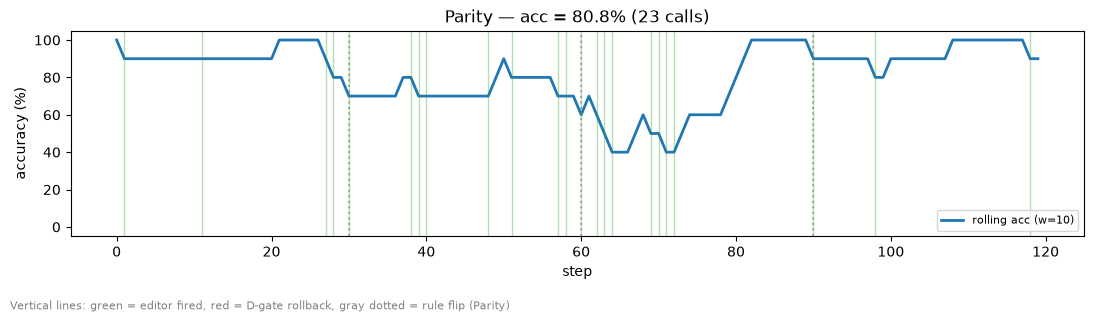

In [5]:
traj_parity = run_task("Parity", length=120, budget=120, tau_i=1.5, alpha=0.9)

## 4 · Task 2 — Guess number *(numeric, abrupt state shifts)*

A hidden integer in [1, 100] shifts to a new random value every 40 steps. The
predictor extracts the first integer from the current prompt as its guess, so the
editor's role is to update that integer toward the current segment's target.

**What to watch:** the black line is the hidden truth (a step function). The blue
line/dots are the agent's predictions. A well-chosen gate should fire shortly after
each state shift, and the blue line should jump to meet the new black level within a
few steps.

Experiment config · GuessNumber                                                         
┏━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Setting     ┃ Value                                                                  ┃
┡━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ Task        │ GuessNumber                                                            │
│ Gate        │ Proportional                                                           │
│ Provider    │ OpenAI                                                                 │
│ Model       │ gpt-4o-mini                                                            │
│ Noise p     │ 0.10                                                                   │
│ Seed        │ 0                                                                      │
│ Length      │ 120                                                                    │
│ Call budget │ 120                                                                    │
│ τ_I         │ 1.5                                                                    │
│ α (decay)   │ 0.9                                                                    │
│ Cache dir   │ /Users/xuzhentao/Desktop/pid_gated_agent_learning_oss/examples/.cache  │
│ Output dir  │ /Users/xuzhentao/Desktop/pid_gated_agent_learning_oss/examples/.output │
└─────────────┴────────────────────────────────────────────────────────────────────────┘

number_guess/P:   0%|          | 0/120 [00:00<?, ?it/s]

  calls=68   edits=68   rollbacks=0   unchanged=6
  final prompt: 'target in [72, 76]'
  figure saved: examples/.output/task-GuessNumber__gate-Proportional__provider-OpenAI__model-gpt-4o-mini__noise-0.10__seed-0__len-120__budget-120__tauI-1.5__alpha-0.9.png


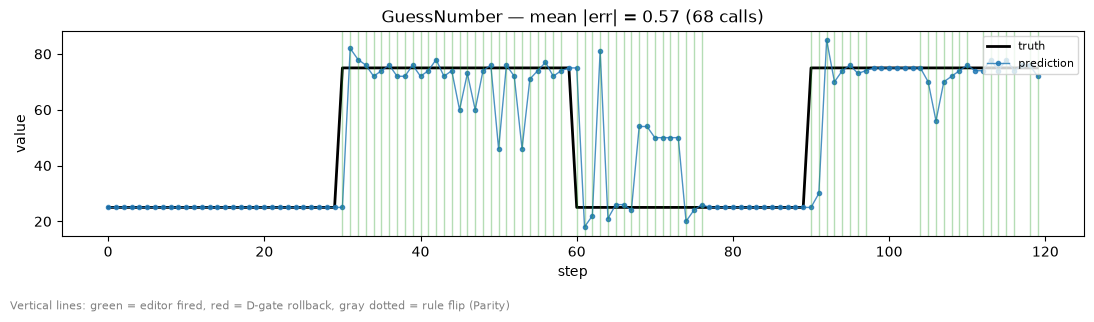

In [6]:
traj_guess = run_task("GuessNumber", length=120, budget=120, tau_i=1.5, alpha=0.9)

## 5 · Task 3 — Track moving target *(numeric, smooth drift)*

The hidden integer follows a smooth sinusoidal trajectory — **no discrete change
points at all**. This is the hardest regime for a reactive gate because there is no
clear moment that "something changed"; evidence builds up gradually.

**What to watch:** can the prediction (blue) follow the sine (black)? Where does the
gate decide to fire? Patient gates (Integral, Derivative) tend to under-react to
smooth drift; a Proportional gate tends to over-react to every bucketed deviation.

Experiment config · MovingTarget                                                        
┏━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Setting     ┃ Value                                                                  ┃
┡━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ Task        │ MovingTarget                                                           │
│ Gate        │ Proportional                                                           │
│ Provider    │ OpenAI                                                                 │
│ Model       │ gpt-4o-mini                                                            │
│ Noise p     │ 0.10                                                                   │
│ Seed        │ 0                                                                      │
│ Length      │ 120                                                                    │
│ Call budget │ 120                                                                    │
│ τ_I         │ 1.5                                                                    │
│ α (decay)   │ 0.9                                                                    │
│ Cache dir   │ /Users/xuzhentao/Desktop/pid_gated_agent_learning_oss/examples/.cache  │
│ Output dir  │ /Users/xuzhentao/Desktop/pid_gated_agent_learning_oss/examples/.output │
└─────────────┴────────────────────────────────────────────────────────────────────────┘

moving_target/P:   0%|          | 0/120 [00:00<?, ?it/s]

  calls=107   edits=107   rollbacks=0   unchanged=0
  final prompt: 'target in [25, 34]'
  figure saved: examples/.output/task-MovingTarget__gate-Proportional__provider-OpenAI__model-gpt-4o-mini__noise-0.10__seed-0__len-120__budget-120__tauI-1.5__alpha-0.9.png


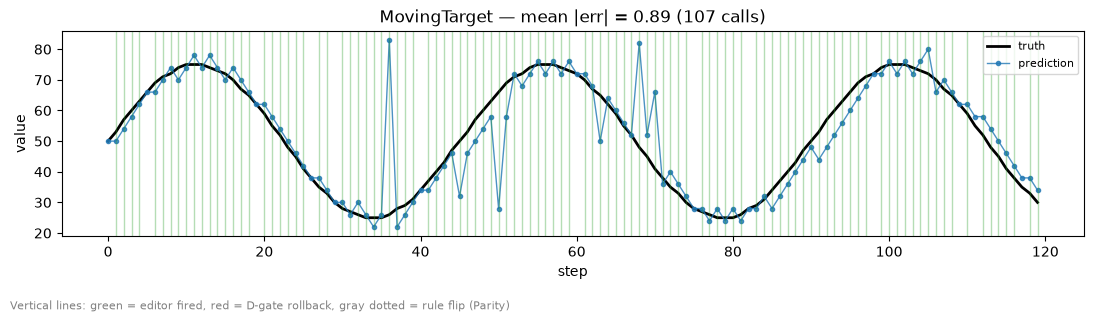

In [7]:
traj_moving = run_task("MovingTarget", length=120, budget=120, tau_i=1.5, alpha=0.9)

## 6 · *Optional:* compare all three gates side-by-side

Runs Proportional / Integral / Derivative gates against the **same** Parity task and
the **same** seed, so the only variable is the gate. This is the plot that most
cleanly shows the paper's claim: later gates in the P → I → D sequence tend to use
fewer editor calls while preserving (or improving) accuracy.

To keep the comparison fair this cell ignores the gate selected above and loops
through all three.

parity/P:   0%|          | 0/120 [00:00<?, ?it/s]

parity/I:   0%|          | 0/120 [00:00<?, ?it/s]

parity/D:   0%|          | 0/120 [00:00<?, ?it/s]

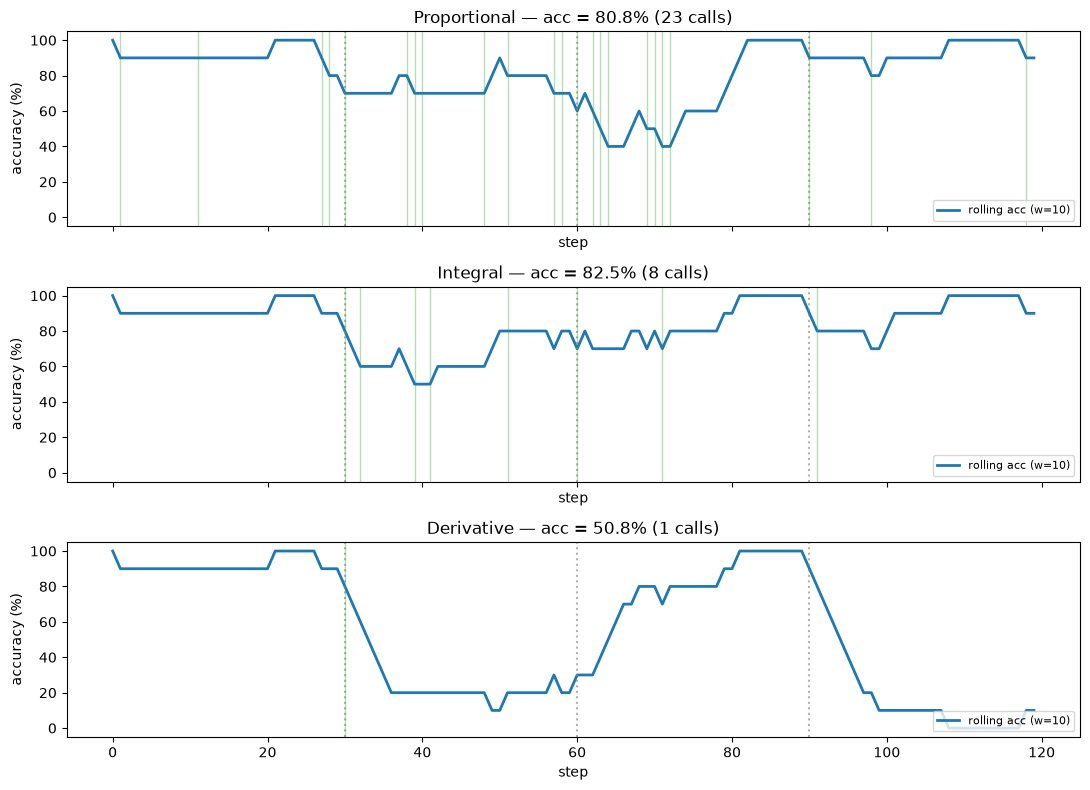

In [8]:
chosen_model = custom_model_w.value.strip() or model_w.value.strip()
provider = build_provider(provider_w.value, chosen_model)
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, gate_name in zip(axes, ["Proportional", "Integral", "Derivative"]):
    gate = build_gate(gate_name, tau_i=1.5, tau_d=0.15, alpha=0.9)
    traj = Scheduler(
        task=Parity(seed=seed_w.value, length=120),
        gate=gate,
        editor=provider,
        noise=noise_w.value,
        seed=seed_w.value,
        call_budget=120,
        history_size=8,
        progress=True,
    ).run()
    plot_parity(ax, traj)
    ax.set_title(f"{gate_name} — acc = {traj.accuracy * 100:.1f}% ({traj.num_calls} calls)")
plt.tight_layout()
plt.show()

## 7 · Try this next

- Raise **Noise p** to 0.3 and re-run the Parity cell with **Proportional** vs.
  **Integral** — the Proportional gate will fire on isolated mislabels while Integral
  waits for repeated evidence.
- Switch to a real provider in section 2 and re-run any task cell. On numeric tasks
  especially, a real LLM will actually move the estimate toward the truth, so you'll
  see the blue prediction line start tracking the black truth line.
- Pass tighter gate hyper-parameters, e.g.
  `run_task("Parity", tau_i=0.8, alpha=0.95)` for faster adaptation at the cost of
  more editor calls.
- See the companion paper for the full experimental protocol, including the
  cost-quality Pareto comparison against TextGrad and GEPA across editor scales.